# Telco Customer Churn Analysis
Session 26 · Task 3

## 1. Load and inspect
Source: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Place the Telco customer CSV in `data/telco/`. The outcome is observed churn status in this snapshot; this notebook does not train a prediction model.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT = Path.cwd().resolve()
if not (ROOT / 'data').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'data').is_dir(), 'Open this notebook from the project root or notebooks folder.'
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
OUT = ROOT / 'reports'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150, bbox_inches='tight')
    plt.show()
def require_columns(frame, columns):
    missing = set(columns) - set(frame.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
def report(name, text):
    (OUT / name).write_text(text, encoding='utf-8')
    print(text)

In [2]:
files=list((ROOT/'data'/'telco').rglob('*.csv'))
if len(files)!=1: raise FileNotFoundError('Place exactly one Telco CSV in data/telco/.')
raw=pd.read_csv(files[0]); raw.columns=raw.columns.str.strip()
display(raw.head()); raw.info(); display(raw.isna().sum().to_frame('missing'))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 2. Cleaning
Blank TotalCharges values become missing, not zero. Numeric negatives are invalidated. Conflicting customer IDs cause an explicit error. Unknown churn labels are excluded from churn denominators, and missing groups remain visible.

In [3]:
require_columns(raw,['customerID','Churn','tenure','MonthlyCharges','TotalCharges','Contract','PaymentMethod','InternetService'])
df=raw.drop_duplicates().copy()
for c in df.select_dtypes(include=['object','string']).columns:
    df[c]=df[c].astype('string').str.strip().replace('',pd.NA)
for c in ['tenure','MonthlyCharges','TotalCharges','SeniorCitizen']:
    if c in df:
        df[c]=pd.to_numeric(df[c],errors='coerce'); df.loc[df[c]<0,c]=np.nan
if 'SeniorCitizen' in df: df.loc[~df.SeniorCitizen.isin([0,1]),'SeniorCitizen']=np.nan
df.loc[df.tenure%1!=0,'tenure']=np.nan
if df.customerID.dropna().duplicated().any(): raise ValueError('Conflicting repeated customer IDs require review.')
missing_id=int(df.customerID.isna().sum()); df=df.dropna(subset=['customerID']).copy()
df['churn']=df.Churn.str.lower().map({'yes':1,'no':0}).astype(float)
df['tenure_group']=pd.cut(df.tenure,[-np.inf,12,24,48,60,np.inf],labels=['0–12','13–24','25–48','49–60','61+'])
display(df.describe(include='all').T); display(df.isna().sum().to_frame('clean_missing'))
print('Exact duplicate rows removed:',len(raw)-len(raw.drop_duplicates()),'Missing customer IDs excluded:',missing_id)
print('Unknown churn outcomes:',df.churn.isna().sum())
print('Missing TotalCharges by tenure:'); display(df[df.TotalCharges.isna()][['tenure','MonthlyCharges']])
base=df.churn.mean(); print(f'Observed churn rate: {base:.2%}')
print('Mean monthly charges:',np.nanmean(df.MonthlyCharges))
df.isna().sum().to_csv(OUT/'telco_missing_values.csv',header=['missing'])

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,clean_missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Exact duplicate rows removed: 0 Missing customer IDs excluded: 0
Unknown churn outcomes: 0
Missing TotalCharges by tenure:


,tenure,MonthlyCharges
488,0.0,52.55
753,0.0,20.25
936,0.0,80.85
1082,0.0,25.75
1340,0.0,56.05
3331,0.0,19.85
3826,0.0,25.35
4380,0.0,20.00
5218,0.0,19.70
6670,0.0,73.35


Observed churn rate: 26.54%
Mean monthly charges: 64.76169246059918


## 3. Segment comparisons
Each rate uses customers with a known churn outcome as its denominator. Wilson 95% intervals describe binomial sampling uncertainty; they do not correct selection bias or confounding. Small segments are not reliable ranking targets.

gender


,customers,known_outcomes,churned,churn_rate,ci_low,ci_high
gender,,,,,,
Female,3488,3488,939.0,0.269209,0.254748,0.284177
Male,3555,3555,930.0,0.261603,0.247418,0.276303


SeniorCitizen


,customers,known_outcomes,churned,churn_rate,ci_low,ci_high
SeniorCitizen,,,,,,
0.0,5901,5901,1393.0,0.236062,0.225400,0.247066
1.0,1142,1142,476.0,0.416813,0.388543,0.445640


Partner


,customers,known_outcomes,churned,churn_rate,ci_low,ci_high
Partner,,,,,,
No,3641,3641,1200.0,0.329580,0.314498,0.345021
Yes,3402,3402,669.0,0.196649,0.183638,0.210344


... (24 outputs left out)

PaymentMethod


,customers,known_outcomes,churned,churn_rate,ci_low,ci_high
PaymentMethod,,,,,,
Bank transfer (automatic),1544,1544,258.0,0.167098,0.149321,0.186529
Credit card (automatic),1522,1522,232.0,0.152431,0.135249,0.171363
Electronic check,2365,2365,1071.0,0.452854,0.432885,0.472976
Mailed check,1612,1612,308.0,0.191067,0.172618,0.210985


tenure_group


,customers,known_outcomes,churned,churn_rate,ci_low,ci_high
tenure_group,,,,,,
0–12,2186,2186,1037.0,0.474382,0.453513,0.495342
13–24,1024,1024,294.0,0.287109,0.260235,0.315575
25–48,1594,1594,325.0,0.203890,0.184834,0.224369
49–60,832,832,120.0,0.144231,0.121992,0.169740
61+,1407,1407,93.0,0.066098,0.054261,0.080298


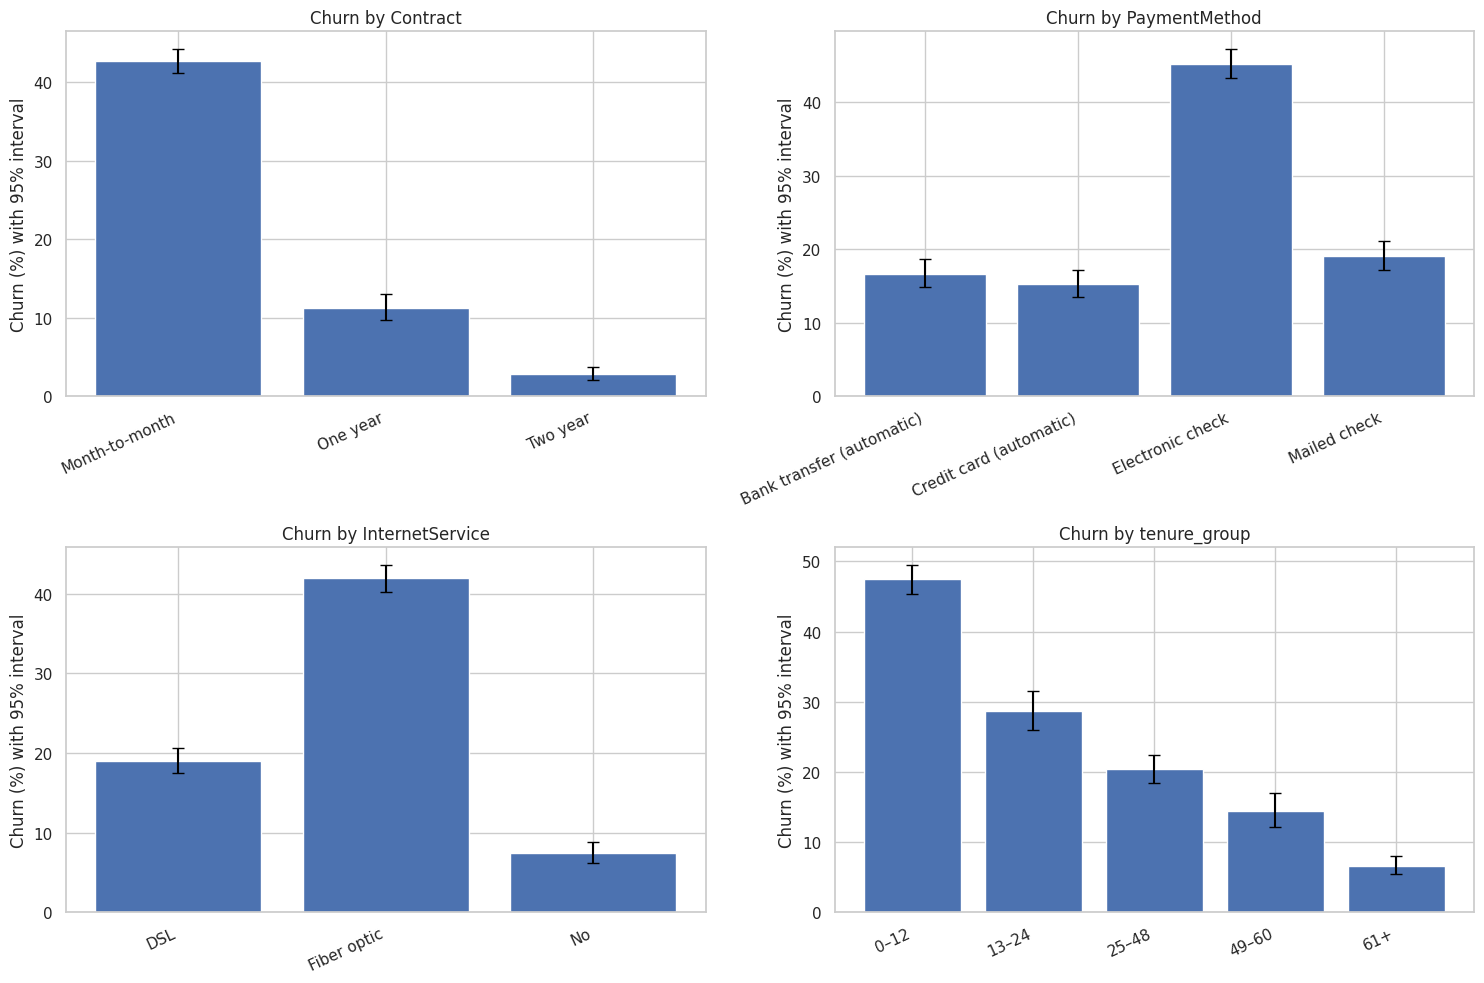

In [4]:
def segment(key):
    g=df.groupby(key,dropna=False,observed=True).agg(customers=('customerID','size'),known_outcomes=('churn','count'),churned=('churn','sum'))
    n=g.known_outcomes.replace(0,np.nan); p=g.churned/n; z=1.96
    den=1+z*z/n; mid=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return g.assign(churn_rate=p,ci_low=(mid-half).clip(0,1),ci_high=(mid+half).clip(0,1))
keys=['gender','SeniorCitizen','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling','PaymentMethod','tenure_group']
tables={k:segment(k) for k in keys if k in df}
for k,g in tables.items():
    print(k); display(g); g.to_csv(OUT/f'telco_{k}.csv')
fig,axes=plt.subplots(2,2,figsize=(15,10))
for ax,key in zip(axes.flat,['Contract','PaymentMethod','InternetService','tenure_group']):
    g=tables[key].dropna(subset=['churn_rate'])
    ax.bar(np.arange(len(g)),100*g.churn_rate)
    ax.errorbar(np.arange(len(g)),100*g.churn_rate,yerr=np.maximum(0,np.vstack([100*(g.churn_rate-g.ci_low),100*(g.ci_high-g.churn_rate)])),fmt='none',color='black',capsize=4)
    ax.set_xticks(np.arange(len(g)),g.index.astype(str),rotation=25,ha='right')
    ax.set(title=f'Churn by {key}',ylabel='Churn (%) with 95% interval')
savefig('telco_segments.png')

## 4. Billing, tenure and interacting segments
Compare distributions rather than only averages. Total charges and tenure naturally accumulate together. Service categories such as “No internet service” are meaningful and are not converted to missing values.

tenure                   MonthlyCharges                    TotalCharges  \
       count       mean median          count       mean  median        count   
Churn                                                                           
No      5174  37.569965   38.0           5174  61.265124  64.425         5163   
Yes     1869  17.979133   10.0           1869  74.441332  79.650         1869   

                            
              mean  median  
Churn                       
No     2555.344141  1683.6  
Yes    1531.796094  703.55

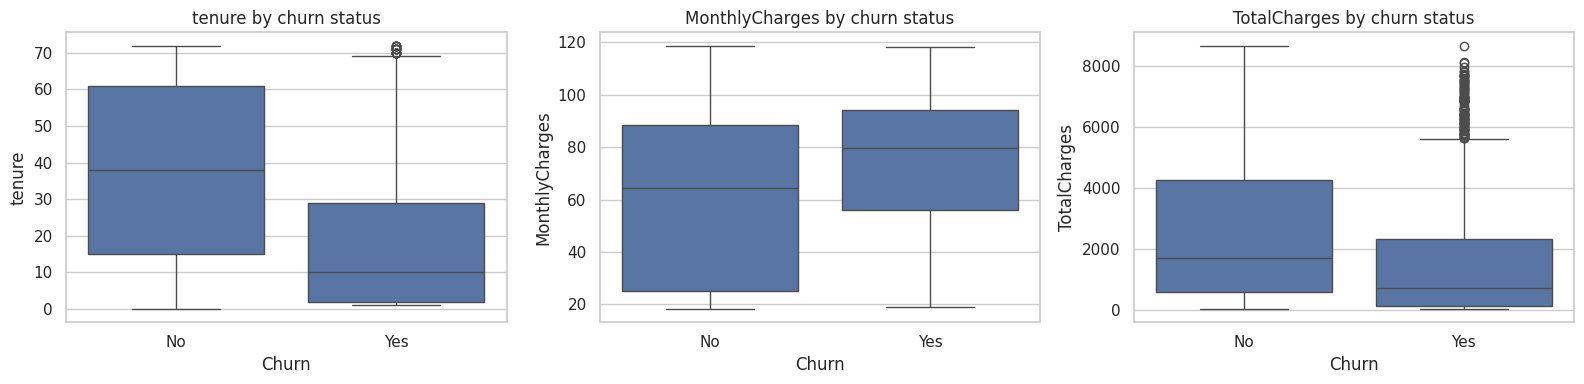

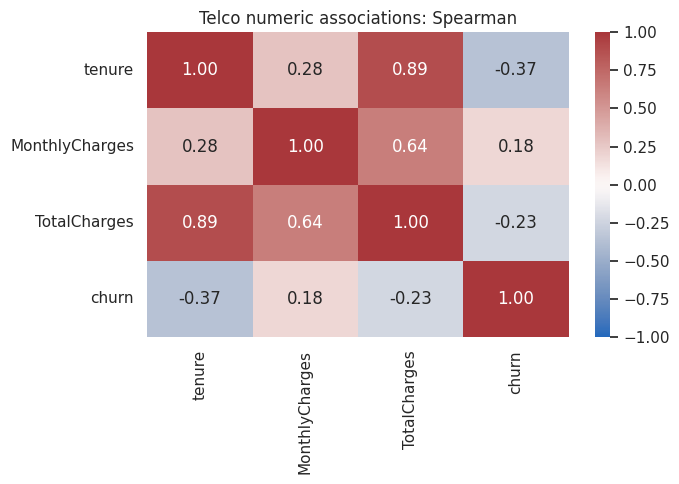

known_outcomes  churn_rate
Contract       InternetService                            
Month-to-month DSL                        1223    0.322159
               Fiber optic                2128    0.546053
               No                          524    0.188931
One year       DSL                         570    0.092982
               Fiber optic                 539    0.192950
               No                          364    0.024725
Two year       DSL                         628    0.019108
               Fiber optic                 429    0.072261
               No                          638    0.007837

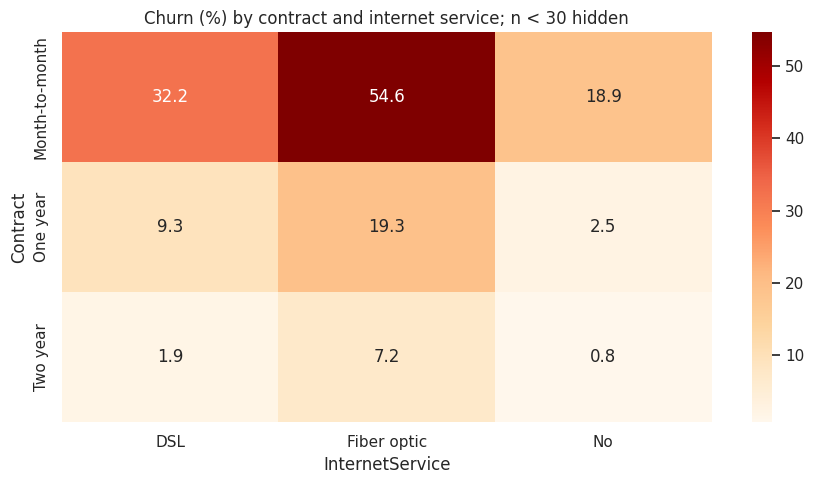

In [5]:
display(df.groupby('Churn')[['tenure','MonthlyCharges','TotalCharges']].agg(['count','mean','median']))
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,c in zip(axes,['tenure','MonthlyCharges','TotalCharges']):
    sns.boxplot(data=df,x='Churn',y=c,ax=ax); ax.set_title(f'{c} by churn status')
savefig('telco_distributions.png')
plt.figure(figsize=(7,5)); sns.heatmap(df[['tenure','MonthlyCharges','TotalCharges','churn']].corr(method='spearman'),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag')
plt.title('Telco numeric associations: Spearman'); savefig('telco_correlations.png')
cross=df.groupby(['Contract','InternetService'],dropna=False).agg(known_outcomes=('churn','count'),churn_rate=('churn','mean'))
display(cross); cross.to_csv(OUT/'telco_contract_internet.csv')
pivot=cross.churn_rate.unstack(); counts=cross.known_outcomes.unstack()
plt.figure(figsize=(9,5)); sns.heatmap(100*pivot,mask=counts<30,annot=True,fmt='.1f',cmap='OrRd')
plt.title('Churn (%) by contract and internet service; n < 30 hidden'); savefig('telco_contract_internet.png')

## 5. Short report and retention hypotheses
Prioritize sufficiently large high-rate groups for investigation, then test interventions. This analysis cannot show that changing a contract or service causes retention.

In [6]:
rank=[]
for key in ['Contract','PaymentMethod','InternetService','tenure_group']:
    for label,row in tables[key].iterrows():
        if row.known_outcomes>=30:
            rank.append((key,str(label),row.churn_rate,int(row.known_outcomes)))
rank=sorted(rank,key=lambda x:x[2],reverse=True)
lines='\n'.join(f'- {k} = {v}: churn {p:.1%}, known outcomes n={count}.' for k,v,p,count in rank[:5])
report('telco_report.md',f"""# Telco Customer Churn — findings
- Source: {files[0].name}.
- Raw rows: {len(raw):,}; cleaned customers: {len(df):,}.
- Known outcomes: {df.churn.notna().sum():,}; observed churn rate: {base:.2%}.
- Median tenure: {df.tenure.median():.1f} months.
- Median monthly charge: {df.MonthlyCharges.median():.2f} dataset currency units.

## Higher-rate segments (at least 30 known outcomes)
{lines}
These segments overlap and should not be added together.

## Retention actions to test
Investigate support complaints and pricing concerns in the identified groups. Trial early-tenure onboarding and service assistance; test contract incentives without assuming causality. Use randomized pilot groups and monitor retention, customer satisfaction and intervention cost before scaling.

## Limitations
Historical observational snapshot; no causal identification, cohort survival analysis or validated prediction model. Unequal tenure creates unequal exposure to churn. Group rates may reflect differences in other customer characteristics. Missing charges remain missing.

## Evidence
See telco_*.csv tables in this directory and ../figures/telco_*.png for segment sizes, confidence intervals, billing distributions and interaction comparisons.
""")

# Telco Customer Churn — findings
- Source: WA_Fn-UseC_-Telco-Customer-Churn.csv.
- Raw rows: 7,043; cleaned customers: 7,043.
- Known outcomes: 7,043; observed churn rate: 26.54%.
- Median tenure: 29.0 months.
- Median monthly charge: 70.35 dataset currency units.

## Higher-rate segments (at least 30 known outcomes)
- tenure_group = 0–12: churn 47.4%, known outcomes n=2186.
- PaymentMethod = Electronic check: churn 45.3%, known outcomes n=2365.
- Contract = Month-to-month: churn 42.7%, known outcomes n=3875.
- InternetService = Fiber optic: churn 41.9%, known outcomes n=3096.
- tenure_group = 13–24: churn 28.7%, known outcomes n=1024.
These segments overlap and should not be added together.

## Retention actions to test
Investigate support complaints and pricing concerns in the identified groups. Trial early-tenure onboarding and service assistance; test contract incentives without assuming causality. Use randomized pilot groups and monitor retention, customer satisfaction and interv